### Bibliotecas

In [1]:
import geemap
import numpy as np
import geopandas as gpd
import geobr
import ee
import json
import os
import pandas as pd
import datetime

In [2]:
# Autenticação

ee.Authenticate()
ee.Initialize(project='ee-wanderamufv')

In [3]:
# Coleção de cenas GOES

coll = ee.ImageCollection('NOAA/GOES/16/MCMIPF')\
    .filterDate('2022-07-01T12:00', '2022-07-01T18:10')

In [5]:
coll.size().getInfo()

37

In [7]:
# Vetor com o limite do Brasil
BR = geobr.read_country(year=2018)

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

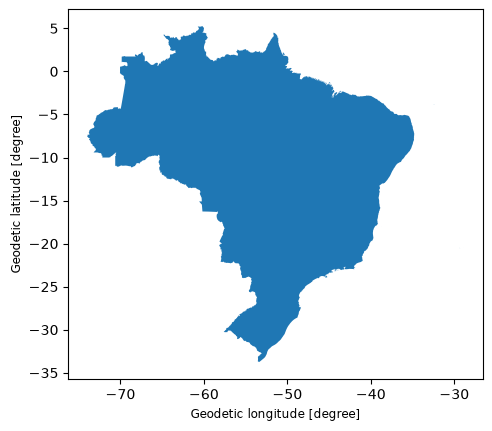

In [8]:
BR.plot()

In [9]:
# Covertendo as coordenadas de geodataframe para json
br_json = BR.to_json()

# Carregando o arquivo json
br_json_coords = json.loads(br_json)

# Selecionando coordenadas
br_coord = br_json_coords['features']

# Convertendo as coordenadas para o tipo FeatureCollection do Earth Engine
aoi = ee.FeatureCollection(br_coord)

In [10]:
# Parâmetros de visualização do GIF

video_args = {
    'dimensions': 600,
    'region': aoi,
    'crs': 'EPSG:3857',
    'framesPerSecond': 10,
    'bands': ['CMI_C02', 'CMI_C03', 'CMI_C01'],
    'min': 0,
    'max': 2000,
    'gamma': 1.3
}

In [11]:
# Diretório de saída

out_gif = 'gif/GOES.gif'

In [24]:
# Gerando o GIF

geemap.download_ee_video(coll, video_args, out_gif)

Generating URL...
Please wait ...
The GIF image has been saved to: c:\Users\letic\Documents\PDIPy_codes2\gif\GOES.gif


In [22]:
# Criando lista de horários

start_time = '2022-07-01 12:00:00'
end_time = '2022-07-01 18:00:00'

times = pd.date_range(
    start=pd.Timestamp(start_time).round('10min'),
    end=pd.Timestamp(end_time).round('10min'),
    freq='10min'
    )

times_list = times.strftime('%Y-%m-%d %H:%M:%S').tolist()

print(times_list)

['2022-07-01 12:00:00', '2022-07-01 12:10:00', '2022-07-01 12:20:00', '2022-07-01 12:30:00', '2022-07-01 12:40:00', '2022-07-01 12:50:00', '2022-07-01 13:00:00', '2022-07-01 13:10:00', '2022-07-01 13:20:00', '2022-07-01 13:30:00', '2022-07-01 13:40:00', '2022-07-01 13:50:00', '2022-07-01 14:00:00', '2022-07-01 14:10:00', '2022-07-01 14:20:00', '2022-07-01 14:30:00', '2022-07-01 14:40:00', '2022-07-01 14:50:00', '2022-07-01 15:00:00', '2022-07-01 15:10:00', '2022-07-01 15:20:00', '2022-07-01 15:30:00', '2022-07-01 15:40:00', '2022-07-01 15:50:00', '2022-07-01 16:00:00', '2022-07-01 16:10:00', '2022-07-01 16:20:00', '2022-07-01 16:30:00', '2022-07-01 16:40:00', '2022-07-01 16:50:00', '2022-07-01 17:00:00', '2022-07-01 17:10:00', '2022-07-01 17:20:00', '2022-07-01 17:30:00', '2022-07-01 17:40:00', '2022-07-01 17:50:00', '2022-07-01 18:00:00']


In [34]:
# Adicionando texto com o horário das cenas

geemap.add_text_to_gif(
    out_gif,
    out_gif,
    xy=('3%', '5%'),
    text_sequence=times_list,
    font_size=30,
    font_color="#00109C"
)

In [35]:
# Visualizando resultado

geemap.show_image(out_gif)

Output()